# Segmentación y clasificación de viviendas (Ames, Iowa)

**Evaluación Parcial N°3: PCA, K-Means y ensambles**

**Dataset:** Housing_Dataset (Ames Housing)

**Integrantes:**
* Milenka Guerra
* Aydan González
* Tomás González
* Nicolas Sagua

**Ramo:** Machine Learning 001D

**Docente:** Mauro Mercado

**Fecha:** 26 de noviembre de 2026

---

## Índice

1. Librerías y configuración
2. Comprensión del problema
3. Preparación de los datos (Actividad 1)

   3.1 Carga de los datos

   3.2 Calidad de los datos
      * 3.2.1 Faltantes reales
      * 3.2.2 Consistencia lógica y corrección
      * 3.2.3 Duplicados e identificadores

   3.3 Alcance y división de los datos
      * 3.3.1 Alcance del análisis
      * 3.3.2 División en entrenamiento, validación y prueba

   3.4 Análisis exploratorio sobre el conjunto de entrenamiento
      * 3.4.1 El precio de venta y la etiqueta de clasificación
      * 3.4.2 Selección de variables
      * 3.4.3 Relación entre las variables seleccionadas

   3.5 Etiqueta, imputación y escalado
      * 3.5.1 Variables y etiqueta
      * 3.5.2 Imputación y escalado
4. PCA (Actividad 2)
5. K-Means (Actividad 3)
6. Ensambles (Actividad 4)
7. Comparación y conclusiones (Actividad 5)
8. Referencias

---
# 1. Librerías y configuración

In [1]:
import warnings
from pathlib import Path

# Manipulación de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

# Preparación de datos
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# PCA y K-Means
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Ensambles
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Métricas
from sklearn.metrics import (silhouette_score, accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

La **semilla** fija garantiza que cualquier persona obtenga los mismos resultados al ejecutar el notebook. Las rutas son relativas al proyecto y, en caso de trabajar en Google Colab, basta con subir el archivo CSV a la sesión, ya que también se busca en la carpeta de trabajo.

In [2]:
warnings.filterwarnings("ignore", category=FutureWarning)

# Reproducibilidad
SEMILLA = 42

# Rutas: carpeta del proyecto en local o carpeta de trabajo en Colab
RUTA_PROYECTO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
NOMBRE_ARCHIVO = "Ames_Iowa_Housing_Dataset.csv"
rutas_posibles = [RUTA_PROYECTO / "data" / "raw" / NOMBRE_ARCHIVO, Path.cwd() / NOMBRE_ARCHIVO, Path("/content") / NOMBRE_ARCHIVO]
RUTA_DATOS_CRUDOS = next((ruta for ruta in rutas_posibles if ruta.exists()), rutas_posibles[0])
RUTA_DATOS_PROCESADOS = RUTA_PROYECTO / "data" / "processed"
RUTA_IMAGENES = RUTA_PROYECTO / "images"
for carpeta in [RUTA_DATOS_PROCESADOS, RUTA_IMAGENES]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Colores y estilo de los gráficos
COLOR_PRINCIPAL = "#2a78d6"
COLOR_SECUNDARIO = "#eb6834"
COLOR_TERCIARIO = "#1baf7a"
COLOR_NEUTRO = "#8a8984"
PALETA = [COLOR_PRINCIPAL, COLOR_SECUNDARIO, COLOR_TERCIARIO, "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

sns.set_theme(style="whitegrid", palette=PALETA)
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 100, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#ebeae6", "lines.linewidth": 2,
})
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

# Formato en miles de dólares para los ejes
formato_dolares = mtick.FuncFormatter(lambda valor, _: f"${valor/1000:,.0f}k")

def guardar_figura(nombre_archivo):
    # Guarda la figura activa en images/
    plt.savefig(RUTA_IMAGENES / f"{nombre_archivo}.png", dpi=120, bbox_inches="tight")

print(f"Archivo de datos encontrado: {RUTA_DATOS_CRUDOS.exists()} ({RUTA_DATOS_CRUDOS})")

Archivo de datos encontrado: True (/content/Ames_Iowa_Housing_Dataset.csv)


---
# 2. Comprensión del problema

En la Evaluación 2 se construyó un modelo de regresión para estimar el precio de una vivienda. En esta evaluación se utilizan los mismos datos con un propósito distinto, que consiste en comprender **cómo se organizan las viviendas** y **qué características separan a las de mayor y menor valor**. El trabajo se divide en tres etapas.

1. **PCA**, para resumir en componentes las características principales de cada vivienda y representarlas en un plano.
2. **K-Means**, para identificar grupos de viviendas similares sin utilizar el precio.
3. **Dos ensambles**, que clasifican si una vivienda se vende **sobre o bajo el precio mediano** a partir de sus características.

De la Evaluación 2 se conservan la lectura correcta del archivo y la corrección de errores de digitación, ya que ambas son reglas fila por fila que no dependen de estadísticas ni del precio. Todas las demás decisiones, como el alcance, la selección de variables y la definición de la etiqueta, se toman de nuevo en esta evaluación.

---
# 3. Preparación de los datos (Actividad 1)

## 3.1 Carga de los datos

El **Ames Housing Dataset** fue publicado por Dean De Cock (2011) y registra 2.930 ventas residenciales ocurridas en Ames, Iowa, entre 2006 y 2010, descritas por 82 columnas.

En muchas columnas el texto `NA` indica que la vivienda **no posee** ese elemento (sin piscina, sin garage), pero pandas lo interpreta por defecto como un dato faltante. A continuación se comparan ambas lecturas.

In [3]:
# Carga inicial
df_original = pd.read_csv(RUTA_DATOS_CRUDOS)

print(f"Filas: {df_original.shape[0]:,} x Columnas: {df_original.shape[1]}")
df_original.head()

Filas: 2,930 x Columnas: 82


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
df_original = pd.read_csv(RUTA_DATOS_CRUDOS)

df_lectura_filtrada = pd.read_csv(
    RUTA_DATOS_CRUDOS,
    # "NA" y "None" se leen como categorías válidas
    keep_default_na=False,
    # solo la celda vacía es un dato faltante
    na_values=[""],
    dtype={"PID": str, "MS SubClass": str},
)

print(f"Nulos con la lectura por defecto: {df_original.isna().sum().sum():,}")
print(f"Nulos con la lectura corregida: {df_lectura_filtrada.isna().sum().sum():,}")
df_lectura_filtrada.head()

Nulos con la lectura por defecto: 15,749
Nulos con la lectura corregida: 719


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,0526301100,020,RL,141.0,31770,Pave,NA,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NA,NA,NA,0,5,2010,WD,Normal,215000
1,2,0526350040,020,RH,80.0,11622,Pave,NA,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,None,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NA,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NA,MnPrv,NA,0,6,2010,WD,Normal,105000
2,3,0526351010,020,RL,81.0,14267,Pave,NA,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NA,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NA,NA,Gar2,12500,6,2010,WD,Normal,172000
3,4,0526353030,020,RL,93.0,11160,Pave,NA,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,None,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NA,NA,NA,0,4,2010,WD,Normal,244000
4,5,0527105010,060,RL,74.0,13830,Pave,NA,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,None,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NA,MnPrv,NA,0,3,2010,WD,Normal,189900


Tras corregir la lectura del archivo, los valores nulos se reducen de 15.749 a 719. De haber eliminado columnas por exceso de nulos con la lectura por defecto, se habría descartado información válida sobre las viviendas.

Cada fila corresponde a una venta y `SalePrice` registra su precio en dólares. En esta evaluación, el precio se utiliza únicamente para construir la variable objetivo de clasificación, `precio_alto`, que toma el valor 1 cuando la vivienda se vendió sobre la mediana del precio y 0 en caso contrario. Esta etiqueta es la que aprenden a predecir los ensambles de la Actividad 4. Por su parte, PCA y K-Means operan sin etiqueta, y `SalePrice` queda excluida de las variables predictoras.

---
## 3.2 Calidad de los datos

Esta sección revisa faltantes reales, reglas lógicas que todo registro debería cumplir y duplicados. Las correcciones que se aplican aquí son reglas fila por fila, por lo que no utilizan estadísticas del conjunto ni el precio.

### 3.2.1 Faltantes reales

In [5]:
faltantes_reales = df_lectura_filtrada.isna().sum()
faltantes_reales = faltantes_reales[faltantes_reales > 0].sort_values(ascending=False).to_frame("faltantes")
faltantes_reales["porcentaje"] = (faltantes_reales["faltantes"] / len(df_lectura_filtrada) * 100).round(2)
faltantes_reales

,faltantes,porcentaje
Lot Frontage,490,16.72
Garage Yr Blt,159,5.43
Mas Vnr Type,23,0.78
Mas Vnr Area,23,0.78
Bsmt Exposure,4,0.14
Garage Finish,2,0.07
Bsmt Half Bath,2,0.07
Bsmt Full Bath,2,0.07
BsmtFin Type 2,2,0.07
Bsmt Cond,1,0.03


In [6]:
sin_anio_garage = df_lectura_filtrada["Garage Yr Blt"].isna()
print("Garage de las viviendas sin año de garage:")
print(df_lectura_filtrada.loc[sin_anio_garage, "Garage Type"].value_counts().to_string())

Garage de las viviendas sin año de garage:
Garage Type
NA        157
Detchd      2


Solo dos columnas tienen faltantes relevantes, y ambas quedan fuera de las variables candidatas:

* **`Garage Yr Blt` (159):** 157 casos son viviendas sin garage (`Garage Type` igual a `NA`), por lo que el año no existe e imputarlo equivaldría a inventar un garage.
* **`Lot Frontage` (490):** falta en el 16,7% de los registros, una proporción demasiado alta para completarla sin introducir información artificial.

En las demás columnas los faltantes son casos aislados y se imputarán con la mediana del conjunto de entrenamiento (sección 3.5.2).

### 3.2.2 Consistencia lógica y corrección

Un dato puede estar presente y aun así ser imposible, como un garage construido en 2207 o una vivienda remodelada antes de su construcción. Estas correcciones siguen reglas lógicas aplicadas a cada fila, de modo que pueden realizarse antes de dividir los datos sin riesgo de fuga de información.

In [7]:
def limpiar_datos(datos_originales):
    # Corrige errores lógicos y de formato, fila por fila
    datos_limpios = datos_originales.copy()

    # Espacios sobrantes en textos (por ejemplo "WD " en Sale Type)
    for columna in datos_limpios.select_dtypes(exclude="number").columns:
        datos_limpios[columna] = datos_limpios[columna].str.strip()

    # Año de garage imposible (2207) -> se reemplaza por el año de construcción de la vivienda
    anio_imposible = datos_limpios["Garage Yr Blt"] > datos_limpios["Yr Sold"] + 1
    datos_limpios.loc[anio_imposible, "Garage Yr Blt"] = datos_limpios.loc[anio_imposible, "Year Built"]

    # Remodelación anterior a la construcción -> se iguala al año de construcción
    remodelacion_imposible = datos_limpios["Year Remod/Add"] < datos_limpios["Year Built"]
    datos_limpios.loc[remodelacion_imposible, "Year Remod/Add"] = datos_limpios.loc[remodelacion_imposible, "Year Built"]

    # Revestimiento incoherente-> manda el tipo cuando dice "None" y manda el área cuando es cero
    sin_tipo_con_area = (datos_limpios["Mas Vnr Type"] == "None") & (datos_limpios["Mas Vnr Area"] > 0)
    datos_limpios.loc[sin_tipo_con_area, "Mas Vnr Area"] = 0
    con_tipo_sin_area = (datos_limpios["Mas Vnr Type"] != "None") & datos_limpios["Mas Vnr Type"].notna() & (datos_limpios["Mas Vnr Area"] == 0)
    datos_limpios.loc[con_tipo_sin_area, "Mas Vnr Type"] = "None"

    return datos_limpios

reglas = {
    "Garage construido después de la venta": lambda d: d["Garage Yr Blt"] > d["Yr Sold"] + 1,
    "Remodelación anterior a la construcción": lambda d: d["Year Remod/Add"] < d["Year Built"],
    "Revestimiento con tipo y área incoherentes": lambda d: ((d["Mas Vnr Type"] == "None") & (d["Mas Vnr Area"] > 0))
                                                          | ((d["Mas Vnr Type"] != "None") & d["Mas Vnr Type"].notna() & (d["Mas Vnr Area"] == 0)),
}

datos_limpios = limpiar_datos(df_lectura_filtrada)
pd.DataFrame({
    "casos_antes": {regla: int(condicion(df_lectura_filtrada).sum()) for regla, condicion in reglas.items()},
    "casos_despues": {regla: int(condicion(datos_limpios).sum()) for regla, condicion in reglas.items()},
})

,casos_antes,casos_despues
Garage construido después de la venta,1,0
Remodelación anterior a la construcción,1,0
Revestimiento con tipo y área incoherentes,10,0


Se corrigieron 12 errores de digitación. Como limitación conocida del dataset, `Year Remod/Add` utiliza 1950 como valor por defecto en viviendas antiguas sin remodelación registrada.

### 3.2.3 Duplicados e identificadores

In [8]:
print(f"Filas duplicadas sin considerar los identificadores: {datos_limpios.drop(columns=['Order', 'PID']).duplicated().sum()}")
print(f"PID distintos: {datos_limpios['PID'].nunique():,} de {len(datos_limpios):,} filas")

Filas duplicadas sin considerar los identificadores: 0
PID distintos: 2,930 de 2,930 filas


No existen duplicados y cada propiedad aparece una sola vez, por lo que `Order` y `PID` solo identifican filas y quedan fuera del análisis.

| Problema | Casos | Tratamiento |
|---|---|---|
| Texto `NA` y `None` leídos como nulos | Miles de celdas | Lectura corregida, ahora representan la categoría "no tiene" |
| `Garage Yr Blt` y `Lot Frontage` con faltantes relevantes | 159 y 490 | Excluidas de las variables candidatas |
| Faltantes aislados en otras columnas | 1 o 2 por columna | Imputación con la mediana de entrenamiento (sección 3.5.2) |
| Errores de digitación en años y revestimiento | 12 | Corregidos con reglas lógicas |
| Identificadores `Order` y `PID` | 2 columnas | No se utilizan |

---
## 3.3 Alcance y división de los datos

### 3.3.1 Alcance del análisis

El autor del dataset recomienda excluir las viviendas de más de 4.000 pies² de superficie habitable, ya que incluyen ventas parciales que no reflejan el valor de mercado (De Cock, 2011). Se adopta esta recomendación porque proviene de la documentación del dataset y se aplica mediante una regla sobre la superficie, sin utilizar el precio ni estadísticas de los datos. Además, StandardScaler, PCA y K-Means dependen de medias y distancias, de modo que unos pocos casos extremos podrían desplazar todos los resultados.

No se filtran ventas según `Sale Condition`. En la Evaluación 2 esa decisión se justificó con experimentos del modelo de regresión, que no aplican a esta evaluación.

In [9]:
datos_limpios = datos_limpios[datos_limpios["Gr Liv Area"] <= 4000].reset_index(drop=True)
print(f"Viviendas dentro del alcance: {len(datos_limpios):,} (se excluyen {len(df_lectura_filtrada) - len(datos_limpios)})")

Viviendas dentro del alcance: 2,925 (se excluyen 5)


### 3.3.2 División en entrenamiento, validación y prueba

La división se realiza **antes de cualquier análisis que utilice el precio o estadísticas de los datos**. Desde este punto, toda decisión se toma únicamente con el conjunto de entrenamiento.

| Grupo | Proporción | Uso |
|---|---|---|
| **Entrenamiento** | 60% | Análisis exploratorio, selección de variables, definición de la etiqueta y ajuste de imputación, escalado, PCA, K-Means y ensambles |
| **Validación** | 20% | Revisión y comparación de los ensambles antes de la medición final |
| **Prueba** | 20% | Medición única y final del desempeño de los dos ensambles |

La división se estratifica por quintiles de precio, de modo que los tres grupos contengan la misma proporción de viviendas de cada rango. La estratificación solo determina a qué grupo pertenece cada vivienda, por lo que no transfiere información de validación ni de prueba a ningún modelo.

In [10]:
quintil_de_precio = pd.qcut(datos_limpios["SalePrice"], q=5, labels=False)

# Primero se separa la prueba (20%) y luego la validación (25% del 80% restante, equivalente al 20% del total)
indices_train_validacion, indices_test = train_test_split(
    datos_limpios.index, test_size=0.20, random_state=SEMILLA, stratify=quintil_de_precio)
indices_train, indices_validacion = train_test_split(
    indices_train_validacion, test_size=0.25, random_state=SEMILLA, stratify=quintil_de_precio.loc[indices_train_validacion])

datos_train = datos_limpios.loc[indices_train].copy()
datos_validacion = datos_limpios.loc[indices_validacion].copy()
datos_test = datos_limpios.loc[indices_test].copy()

pd.DataFrame({
    "viviendas": [len(conjunto) for conjunto in (datos_train, datos_validacion, datos_test)],
    "porcentaje_del_total": [f"{len(conjunto) / len(datos_limpios):.0%}" for conjunto in (datos_train, datos_validacion, datos_test)],
    "mediana_precio": [f"${conjunto['SalePrice'].median():,.0f}" for conjunto in (datos_train, datos_validacion, datos_test)],
}, index=["Entrenamiento", "Validación", "Prueba"])

,viviendas,porcentaje_del_total,mediana_precio
Entrenamiento,1755,60%,"$160,000"
Validación,585,20%,"$160,000"
Prueba,585,20%,"$160,500"


---
## 3.4 Análisis exploratorio sobre el conjunto de entrenamiento

Todo el análisis de esta sección utiliza **solo `datos_train`**, de modo que ninguna decisión se apoya en información de validación ni de prueba.

In [11]:
precio_train = datos_train["SalePrice"]

### 3.4.1 El precio de venta y la etiqueta de clasificación

El precio define la etiqueta de clasificación, por lo que conviene conocer su forma y su mediana dentro del entrenamiento.

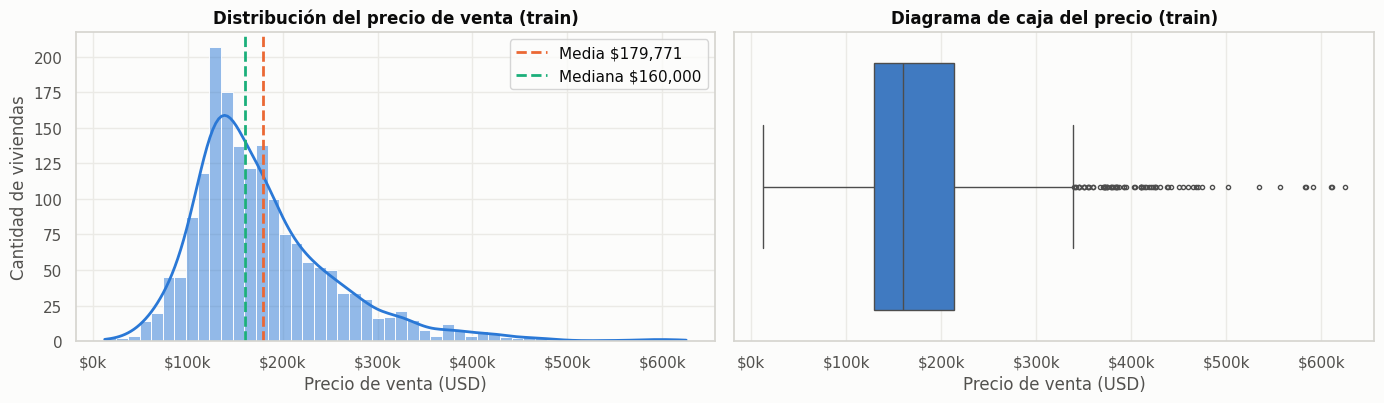

Asimetría del precio: 1.61


In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.histplot(precio_train, bins=50, kde=True, color=COLOR_PRINCIPAL, ax=ejes[0])
ejes[0].axvline(precio_train.mean(), color=COLOR_SECUNDARIO, linestyle="--", label=f"Media ${precio_train.mean():,.0f}")
ejes[0].axvline(precio_train.median(), color=COLOR_TERCIARIO, linestyle="--", label=f"Mediana ${precio_train.median():,.0f}")
ejes[0].xaxis.set_major_formatter(formato_dolares)
ejes[0].set_title("Distribución del precio de venta (train)")
ejes[0].set_xlabel("Precio de venta (USD)")
ejes[0].set_ylabel("Cantidad de viviendas")
ejes[0].legend()

sns.boxplot(x=precio_train, color=COLOR_PRINCIPAL, ax=ejes[1], fliersize=3)
ejes[1].xaxis.set_major_formatter(formato_dolares)
ejes[1].set_title("Diagrama de caja del precio (train)")
ejes[1].set_xlabel("Precio de venta (USD)")
plt.tight_layout()
guardar_figura("01_distribucion_precio")
plt.show()

print(f"Asimetría del precio: {precio_train.skew():.2f}")

El precio presenta una cola larga hacia las viviendas de mayor valor y la media supera a la mediana. Por este motivo, la **mediana** se utiliza como punto de corte de la etiqueta, dado que no se ve arrastrada por los pocos casos de precio muy alto y genera dos clases de igual tamaño.

### 3.4.2 Selección de variables

Las variables se eligen mediante una regla explícita, calculada solo con entrenamiento, en lugar de reutilizar la lista de la evaluación 2.

1. **Candidatas:** todas las variables numéricas, salvo los identificadores, el precio y las dos columnas excluidas en las secciones pasadas.
2. **Relevancia:** se conservan las que tienen una correlación de Spearman con el precio de al menos 0.5 en valor absoluto.
3. **Redundancia:** en cada par de candidatas con correlación mayor a 0.8 entre sí, se elimina la que se relaciona menos con el precio, ya que ambas aportan casi la misma información.

In [13]:
COLUMNAS_EXCLUIDAS = ["Order", "SalePrice", "Garage Yr Blt", "Lot Frontage"]
UMBRAL_RELEVANCIA = 0.5
UMBRAL_REDUNDANCIA = 0.8

columnas_candidatas = [columna for columna in datos_train.select_dtypes(include="number").columns if columna not in COLUMNAS_EXCLUIDAS]
correlacion_con_precio = datos_train[columnas_candidatas].corrwith(precio_train, method="spearman")
relevancia = correlacion_con_precio.abs().sort_values(ascending=False)
variables_relevantes = relevancia[relevancia >= UMBRAL_RELEVANCIA].index.tolist()

# Pares redundantes, revisados de mayor a menor correlación
correlacion_entre_relevantes = datos_train[variables_relevantes].corr(method="spearman").abs()
pares_redundantes = sorted(
    [(variable_a, variable_b, correlacion_entre_relevantes.loc[variable_a, variable_b])
     for posicion, variable_a in enumerate(variables_relevantes) for variable_b in variables_relevantes[posicion + 1:]
     if correlacion_entre_relevantes.loc[variable_a, variable_b] > UMBRAL_REDUNDANCIA],
    key=lambda par: par[2], reverse=True)

variables_eliminadas = {}
for variable_a, variable_b, correlacion in pares_redundantes:
    if variable_a in variables_eliminadas or variable_b in variables_eliminadas:
        continue
    conservada, eliminada = (variable_a, variable_b) if relevancia[variable_a] >= relevancia[variable_b] else (variable_b, variable_a)
    variables_eliminadas[eliminada] = f"Redundante con {conservada} ({correlacion:.2f})"

VARIABLES_SELECCIONADAS = [variable for variable in variables_relevantes if variable not in variables_eliminadas]

tabla_seleccion = pd.DataFrame({
    "correlacion_spearman_con_precio": correlacion_con_precio[variables_relevantes].round(3),
    "decision": ["Seleccionada" if variable in VARIABLES_SELECCIONADAS else variables_eliminadas[variable] for variable in variables_relevantes],
})

display(tabla_seleccion)

,correlacion_spearman_con_precio,decision
Overall Qual,0.802,Seleccionada
Gr Liv Area,0.712,Seleccionada
Garage Cars,0.683,Seleccionada
Year Built,0.670,Seleccionada
Garage Area,0.651,Redundante con Garage Cars (0.87)
Full Bath,0.605,Seleccionada
Total Bsmt SF,0.599,Seleccionada
Year Remod/Add,0.587,Seleccionada
1st Flr SF,0.575,Redundante con Total Bsmt SF (0.81)
Fireplaces,0.537,Seleccionada


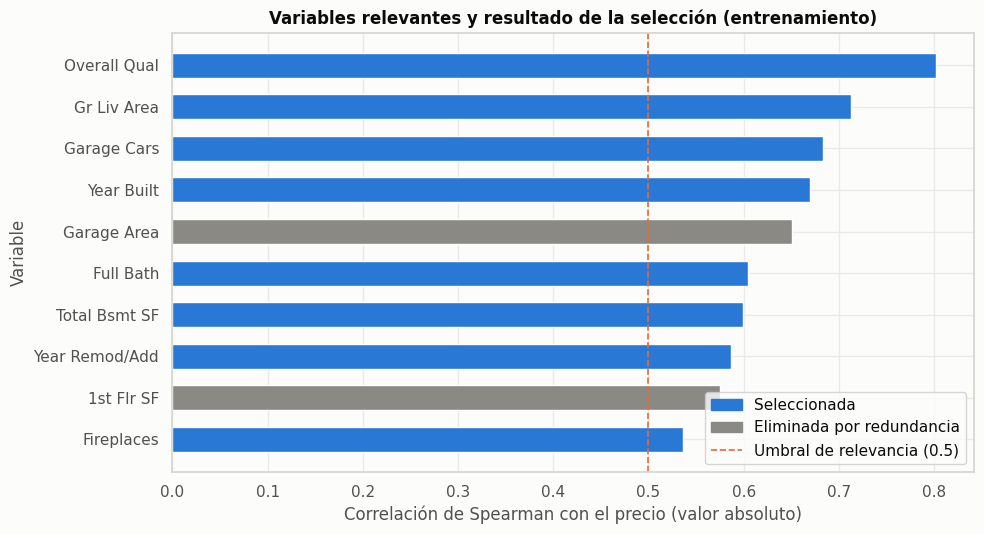

Variables seleccionadas (8): Overall Qual, Gr Liv Area, Garage Cars, Year Built, Full Bath, Total Bsmt SF, Year Remod/Add, Fireplaces


In [14]:
fig, eje = plt.subplots(figsize=(10, 5.5))
colores = [COLOR_PRINCIPAL if variable in VARIABLES_SELECCIONADAS else COLOR_NEUTRO for variable in variables_relevantes]
eje.barh(variables_relevantes[::-1], relevancia[variables_relevantes].values[::-1], color=colores[::-1], height=0.6)
eje.axvline(UMBRAL_RELEVANCIA, color=COLOR_SECUNDARIO, linestyle="--", linewidth=1.2)
eje.set_xlabel("Correlación de Spearman con el precio (valor absoluto)")
eje.set_ylabel("Variable")
eje.set_title("Variables relevantes y resultado de la selección (entrenamiento)")

eje.legend(handles=[
    Patch(color=COLOR_PRINCIPAL, label="Seleccionada"),
    Patch(color=COLOR_NEUTRO, label="Eliminada por redundancia"),
    Line2D([0], [0], color=COLOR_SECUNDARIO, linestyle="--", linewidth=1.2, label=f"Umbral de relevancia ({UMBRAL_RELEVANCIA})"),
], loc="lower right")
plt.tight_layout()
guardar_figura("02_seleccion_variables")
plt.show()

print(f"Variables seleccionadas ({len(VARIABLES_SELECCIONADAS)}): {', '.join(VARIABLES_SELECCIONADAS)}")

La regla selecciona ocho variables que cubren la **calidad** de la construcción (`Overall Qual`), el **tamaño** (`Gr Liv Area`, `Total Bsmt SF`, `Garage Cars`), el **equipamiento** (`Full Bath`, `Fireplaces`) y la **antigüedad** (`Year Built`, `Year Remod/Add`). Se eliminan `Garage Area`, que repite la información de `Garage Cars` (correlación de 0,87), y `1st Flr SF`, que repite la de `Total Bsmt SF` (0,81).

### 3.4.3 Relación entre las variables seleccionadas

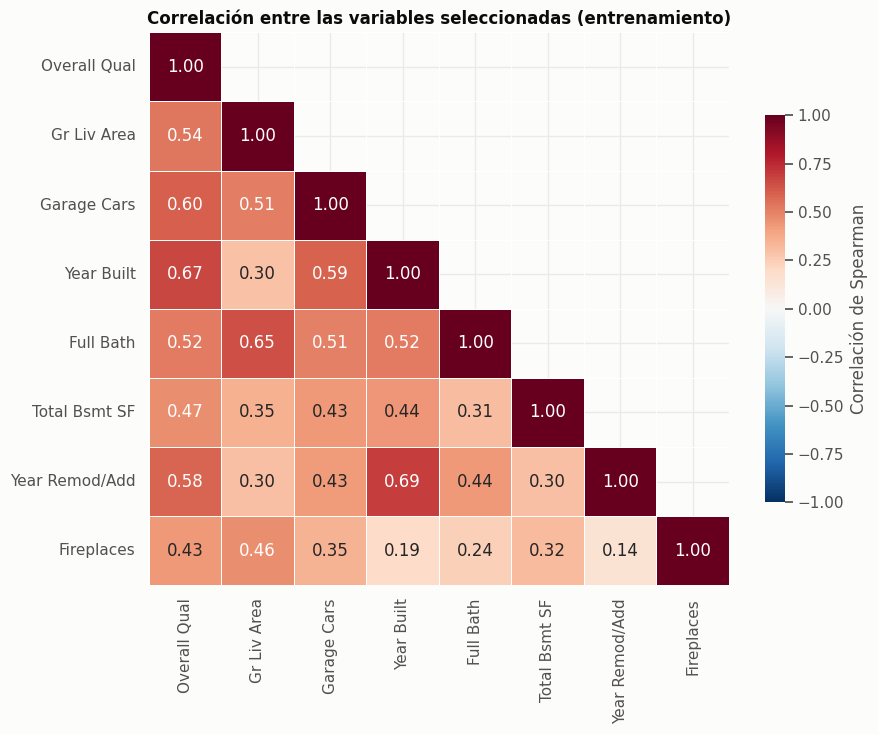

In [15]:
matriz_correlacion = datos_train[VARIABLES_SELECCIONADAS].corr(method="spearman")

fig, eje = plt.subplots(figsize=(9, 7.5))
mascara_triangular = np.triu(np.ones_like(matriz_correlacion, dtype=bool), k=1)
sns.heatmap(matriz_correlacion, mask=mascara_triangular, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.7, "label": "Correlación de Spearman"}, ax=eje)
eje.set_title("Correlación entre las variables seleccionadas (entrenamiento)")
plt.tight_layout()
guardar_figura("03_matriz_correlacion")
plt.show()

Todas las variables seleccionadas se relacionan positivamente entre sí, con correlaciones entre 0,14 y 0,69.

**Hipótesis a contrastar en la sección 4:** la primera componente principal resumiría un eje general de "vivienda grande, moderna y de buena calidad" frente a "vivienda pequeña, antigua y sencilla".

---
## 3.5 Etiqueta, imputación y escalado

### 3.5.1 Variables y etiqueta

Las variables seleccionadas se utilizan en todas las actividades, como entrada de PCA y K-Means y como predictoras de los ensambles. La etiqueta `precio_alto` toma el valor 1 cuando la vivienda se vendió sobre la **mediana del precio de entrenamiento** y 0 en caso contrario. Esa misma mediana se aplica a validación y prueba, de modo que la definición de la etiqueta no utiliza información de esos conjuntos.

In [16]:
MEDIANA_PRECIO_TRAIN = precio_train.median()

def separar_variables_y_etiqueta(datos_entrada):
    # Predictoras seleccionadas y etiqueta binaria según la mediana de entrenamiento
    etiqueta = (datos_entrada["SalePrice"] > MEDIANA_PRECIO_TRAIN).astype(int).rename("precio_alto")
    return datos_entrada[VARIABLES_SELECCIONADAS], etiqueta

X_train, y_train = separar_variables_y_etiqueta(datos_train)
X_validacion, y_validacion = separar_variables_y_etiqueta(datos_validacion)
X_test, y_test = separar_variables_y_etiqueta(datos_test)

print(f"Mediana del precio en entrenamiento: ${MEDIANA_PRECIO_TRAIN:,.0f}")
print("Variable objetivo: precio_alto\n")
print(pd.DataFrame({
    "viviendas": [len(y_train), len(y_validacion), len(y_test)],
    "proporcion_clase_1": [y_train.mean().round(3), y_validacion.mean().round(3), y_test.mean().round(3)],
}, index=["Entrenamiento", "Validación", "Prueba"]))

X_train.head()

Mediana del precio en entrenamiento: $160,000
Variable objetivo: precio_alto

               viviendas  proporcion_clase_1
Entrenamiento       1755               0.500
Validación           585               0.492
Prueba               585               0.503


,Overall Qual,Gr Liv Area,Garage Cars,Year Built,Full Bath,Total Bsmt SF,Year Remod/Add,Fireplaces
1004,6,1633,2.0,1998,2,932.0,1998,1
1428,8,1511,3.0,1995,2,1401.0,1995,1
1285,5,1539,2.0,1904,2,650.0,2002,1
1676,6,1218,1.0,1973,1,672.0,1973,0
1306,7,3493,3.0,1880,3,1470.0,2002,1


Las dos clases quedan equilibradas, cerca del 50% en los tres conjuntos, por lo que Accuracy es una métrica adecuada junto con Precision, Recall y F1.

### 3.5.2 Imputación y escalado

In [17]:
pd.DataFrame({
    "faltantes_train": X_train.isna().sum(),
    "faltantes_validacion": X_validacion.isna().sum(),
    "faltantes_test": X_test.isna().sum(),
}).query("faltantes_train + faltantes_validacion + faltantes_test > 0")

,faltantes_train,faltantes_validacion,faltantes_test
Garage Cars,1,0,0
Total Bsmt SF,1,0,0


Los faltantes son casos aislados, de modo que una imputación con la **mediana** resulta suficiente. Luego, StandardScaler transforma cada variable mediante

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

con lo que todas quedan con media 0 y desviación estándar 1. La imputación y el escalado se agrupan en un pipeline que se **ajusta solo con entrenamiento** y luego se aplica sin cambios a validación y prueba. Así, ninguna mediana, media ni desviación proviene de esos conjuntos.

In [18]:
preprocesamiento = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
])

def escalar(X_entrada):
    return pd.DataFrame(preprocesamiento.transform(X_entrada), columns=VARIABLES_SELECCIONADAS, index=X_entrada.index)

# único ajuste, solo con entrenamiento
preprocesamiento.fit(X_train)

X_train_escalado = escalar(X_train)
X_validacion_escalado = escalar(X_validacion)
X_test_escalado = escalar(X_test)

# Datos preparados para las siguientes actividades
X_train_escalado.join(y_train).to_csv(RUTA_DATOS_PROCESADOS / "entrenamiento_escalado.csv", index=False)
X_validacion_escalado.join(y_validacion).to_csv(RUTA_DATOS_PROCESADOS / "validacion_escalado.csv", index=False)
X_test_escalado.join(y_test).to_csv(RUTA_DATOS_PROCESADOS / "prueba_escalado.csv", index=False)

pd.DataFrame({
    "desviacion_antes": X_train.std(),
    "media_despues": X_train_escalado.mean(),
    "desviacion_despues": X_train_escalado.std(),
}).round(2)

,desviacion_antes,media_despues,desviacion_despues
Overall Qual,1.40,-0.0,1.0
Gr Liv Area,478.76,-0.0,1.0
Garage Cars,0.77,0.0,1.0
Year Built,30.49,0.0,1.0
Full Bath,0.55,-0.0,1.0
Total Bsmt SF,419.80,-0.0,1.0
Year Remod/Add,21.02,0.0,1.0
Fireplaces,0.64,0.0,1.0


Antes del escalado, las desviaciones van desde menos de 1 (baños, chimeneas) hasta cientos de pies² (superficies). Después, en entrenamiento todas quedan con media 0 y desviación 1. En validación y prueba los valores quedan cercanos, pero no idénticos, lo cual es esperable porque se transforman con los parámetros de entrenamiento.

**Pregunta: ¿por qué conviene escalar las variables antes de aplicar PCA y K-Means?**

Porque ambos métodos dependen de la magnitud de los valores. En el caso de PCA, el método busca las direcciones de mayor varianza, de modo que sin escalar, la superficie habitable acapararía la primera componente solo por estar medida en pies², mientras que la calidad general, que varía entre 1 y 10, apenas influiría.

Por otra parte, K-Means agrupa según la distancia euclidiana, por lo que una diferencia de 500 pies² dominaría frente a una diferencia de 3 puntos de calidad.

Al aplicar el escalado, cada variable contribuye según la información que aporta y deja de pesar su unidad de medida.

---
# 4. PCA (Actividad 2)

PCA se ajusta **solo con `X_train_escalado`**, sin la etiqueta. Primero se ajusta con todas las componentes posibles para observar cómo se reparte la varianza entre ellas, y luego con las dos componentes que pide la pauta.

## 4.1 Componentes y varianza explicada

In [19]:
# PCA con todas las componentes, solo para describir cómo se reparte la varianza
pca_completo = PCA(random_state=SEMILLA).fit(X_train_escalado)
nombres_componentes = [f"PC{numero}" for numero in range(1, pca_completo.n_components_ + 1)]

tabla_varianza = pd.DataFrame({
    "varianza_explicada_pct": pca_completo.explained_variance_ratio_ * 100,
    "varianza_acumulada_pct": pca_completo.explained_variance_ratio_.cumsum() * 100,
}, index=nombres_componentes).round(2)


# PCA con las dos componentes que pide la pauta
pca = PCA(n_components=2, random_state=SEMILLA)
componentes_train = pd.DataFrame(pca.fit_transform(X_train_escalado), columns=["PC1", "PC2"], index=X_train_escalado.index)

varianza_pc1, varianza_pc2 = pca.explained_variance_ratio_ * 100
print(f"Varianza explicada por PC1: {varianza_pc1:.2f}%")
print(f"Varianza explicada por PC2: {varianza_pc2:.2f}%")
print(f"Varianza acumulada por PC1 y PC2: {varianza_pc1 + varianza_pc2:.2f}%")

display(tabla_varianza)

Varianza explicada por PC1: 49.59%
Varianza explicada por PC2: 14.05%
Varianza acumulada por PC1 y PC2: 63.64%


,varianza_explicada_pct,varianza_acumulada_pct
PC1,49.59,49.59
PC2,14.05,63.64
PC3,10.41,74.04
PC4,7.60,81.64
PC5,6.65,88.29
PC6,5.02,93.31
PC7,3.85,97.16
PC8,2.84,100.00


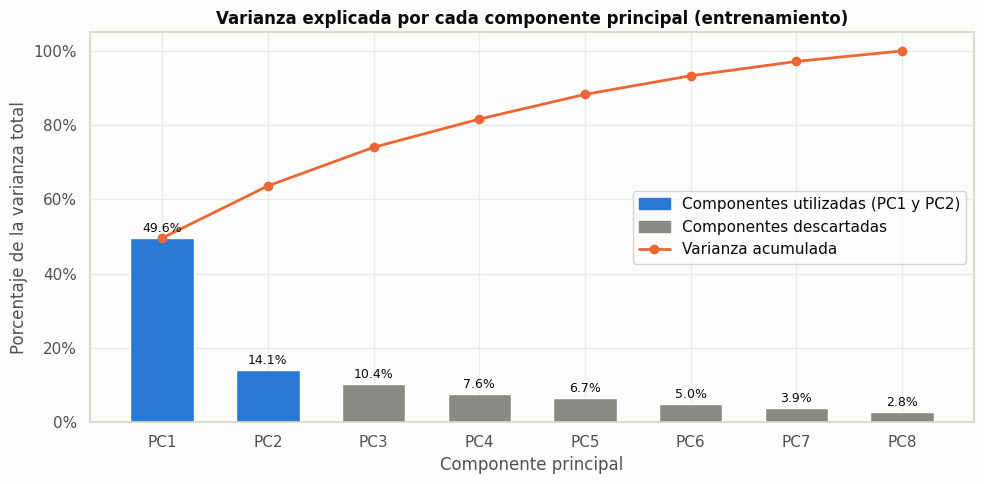

In [20]:
fig, eje = plt.subplots(figsize=(10, 5))
colores_barras = [COLOR_PRINCIPAL if posicion < 2 else COLOR_NEUTRO for posicion in range(len(nombres_componentes))]
barras = eje.bar(nombres_componentes, tabla_varianza["varianza_explicada_pct"], color=colores_barras, width=0.6)
eje.bar_label(barras, fmt="%.1f%%", fontsize=9, padding=2)
eje.plot(nombres_componentes, tabla_varianza["varianza_acumulada_pct"], color=COLOR_SECUNDARIO, marker="o", label="Varianza acumulada")

eje.set_title("Varianza explicada por cada componente principal (entrenamiento)")
eje.set_xlabel("Componente principal")
eje.set_ylabel("Porcentaje de la varianza total")
eje.set_ylim(0, 105)
eje.yaxis.set_major_formatter(mtick.PercentFormatter())
eje.legend(handles=[
    Patch(color=COLOR_PRINCIPAL, label="Componentes utilizadas (PC1 y PC2)"),
    Patch(color=COLOR_NEUTRO, label="Componentes descartadas"),
    Line2D([0], [0], color=COLOR_SECUNDARIO, marker="o", label="Varianza acumulada"),
], loc="center right")
plt.tight_layout()

guardar_figura("04_pca_varianza_explicada")
plt.show()

PC1 concentra casi la mitad de la varianza total (49,6%), y PC2 agrega un 14,1%, de modo que entre ambas conservan el **63,6%** de la información de las ocho variables. PC3 aporta un 10,4% y las siguientes menos de un 8% cada una, por lo que el gráfico muestra un descenso marcado después de PC1. Esto indica que las variables comparten un patrón común fuerte que PC1 logra resumir en una sola dimensión.

## 4.2 Proyección de las viviendas en el plano PC1 y PC2

Cada punto corresponde a una vivienda de entrenamiento ubicada según sus dos componentes. Los colores muestran la etiqueta `precio_alto` **solo como apoyo visual**, ya que PCA se ajustó sin ella.

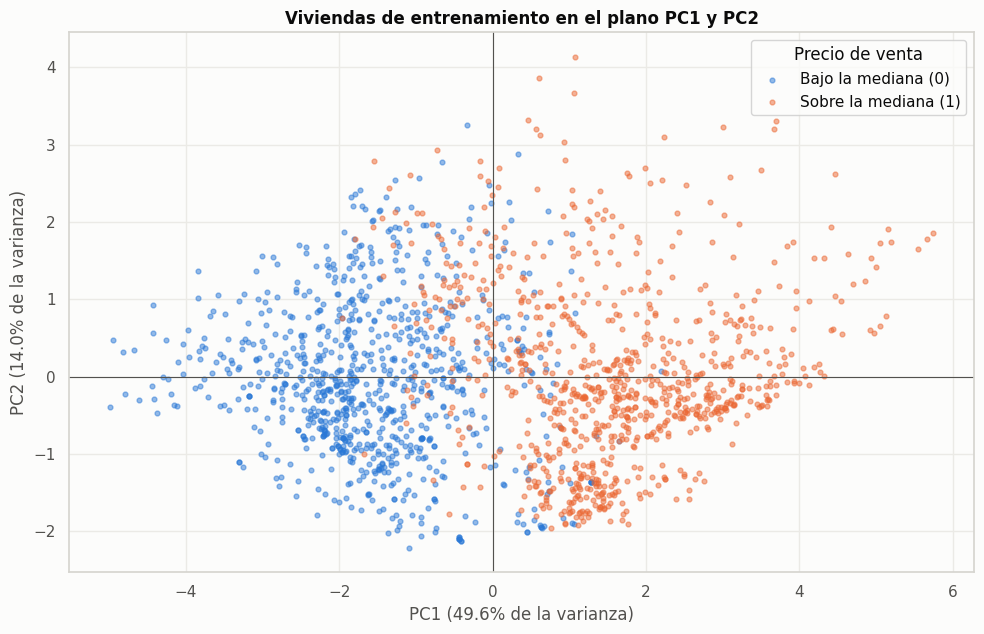

,PC1,PC2
precio_alto,,
0,-1.57,-0.04
1,1.57,0.04


In [21]:
fig, eje = plt.subplots(figsize=(10, 6.5))
for clase, color, nombre in [(0, COLOR_PRINCIPAL, "Bajo la mediana (0)"), (1, COLOR_SECUNDARIO, "Sobre la mediana (1)")]:
    viviendas_clase = componentes_train[y_train == clase]
    eje.scatter(viviendas_clase["PC1"], viviendas_clase["PC2"], s=12, alpha=0.5, color=color, label=nombre)

eje.axhline(0, color="#52514e", linewidth=0.8)
eje.axvline(0, color="#52514e", linewidth=0.8)
eje.set_title("Viviendas de entrenamiento en el plano PC1 y PC2")
eje.set_xlabel(f"PC1 ({varianza_pc1:.1f}% de la varianza)")
eje.set_ylabel(f"PC2 ({varianza_pc2:.1f}% de la varianza)")
eje.legend(title="Precio de venta")
plt.tight_layout()
guardar_figura("05_pca_dispersion")
plt.show()

componentes_train.groupby(y_train.rename("precio_alto")).mean().round(2)

Las viviendas forman una nube continua sin grupos separados a simple vista, sin embargo, el color revela un patrón claro a lo largo de PC1. Las viviendas bajo la mediana se concentran a la izquierda (promedio de PC1 cercano a −1,6) y las que están sobre la mediana a la derecha (cercano a 1,6), mientras que en PC2 ambas clases se superponen casi por completo.

Aunque PCA no utilizó el precio, la primera componente quedó alineada con el valor de las viviendas.

## 4.3 Interpretación de las componentes

Las **cargas** indican cuánto pesa cada variable original en cada componente. Una carga alta en valor absoluto significa que la variable influye mucho en esa componente, y el signo indica la dirección de esa influencia.

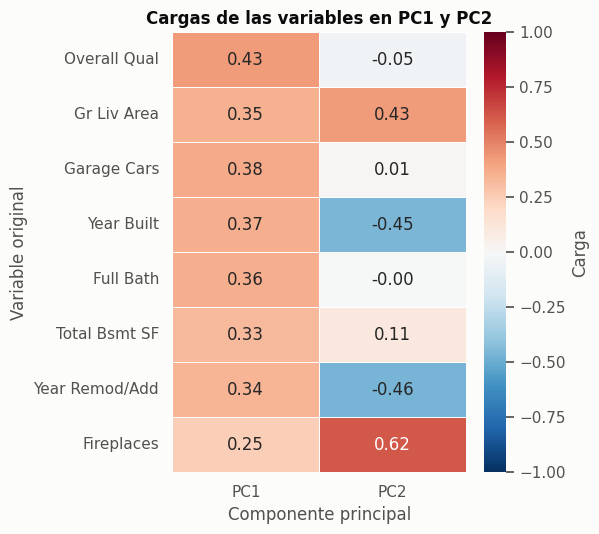

In [22]:
cargas = pd.DataFrame(pca.components_.T, columns=["PC1", "PC2"], index=VARIABLES_SELECCIONADAS)

fig, eje = plt.subplots(figsize=(6, 5.5))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=0.5,
            cbar_kws={"label": "Carga"}, ax=eje)
eje.set_title("Cargas de las variables en PC1 y PC2")
eje.set_xlabel("Componente principal")
eje.set_ylabel("Variable original")
plt.tight_layout()

guardar_figura("06_pca_cargas")
plt.show()

**PC1** tiene cargas del mismo signo y de magnitud parecida (entre 0,25 y 0,43) en las ocho variables, con `Overall Qual` como la más influyente. Por lo tanto, PC1 funciona como un **índice general de la vivienda**: aumenta cuando la casa es más grande, más nueva, de mejor calidad y mejor equipada. Esto **confirma la hipótesis** planteada en la sección 3.4.3.

**PC2** contrapone dos grupos de variables. Por un lado están `Fireplaces` (0,62) y `Gr Liv Area` (0,43), y por el otro `Year Built` (−0,46) y `Year Remod/Add` (−0,46). PC2 distingue entonces a las viviendas **amplias y con chimenea, pero más antiguas**, de las viviendas **más recientes de tamaño similar**. Este contraste explica por qué PC2 casi no separa las clases de precio, ya que describe un estilo de vivienda más que su valor.

## 4.4 Reconstrucción y varianza conservada por variable

Con `inverse_transform` se reconstruyen aproximadamente las ocho variables a partir de PC1 y PC2. Para cada variable original *j*, el porcentaje de varianza conservada se calcula como

$$\text{Varianza conservada}_j = \left(1 - \frac{\sum_i (x_{ij} - \hat{x}_{ij})^2}{\sum_i (x_{ij} - \bar{x}_j)^2}\right) \times 100$$

donde $\hat{x}_{ij}$ es el valor reconstruido. Si la reconstrucción coincide con el valor original el porcentaje es 100%, y mientras mayor sea el error de reconstrucción menor es el porcentaje.

In [23]:
X_train_reconstruido = pd.DataFrame(pca.inverse_transform(componentes_train), columns=VARIABLES_SELECCIONADAS, index=X_train_escalado.index)

error_reconstruccion = ((X_train_escalado - X_train_reconstruido) ** 2).sum()
variacion_original = ((X_train_escalado - X_train_escalado.mean()) ** 2).sum()

tabla_varianza_conservada = pd.DataFrame({
    "variable": VARIABLES_SELECCIONADAS,
    "varianza_conservada_pct": ((1 - error_reconstruccion / variacion_original) * 100).round(1).values,
}).sort_values("varianza_conservada_pct", ascending=False).reset_index(drop=True)

print(f"Promedio de la varianza conservada por variable: {tabla_varianza_conservada['varianza_conservada_pct'].mean():.1f}%")
print(f"Varianza total explicada por PC1 y PC2: {varianza_pc1 + varianza_pc2:.1f}%")

display(tabla_varianza_conservada)

Promedio de la varianza conservada por variable: 100.0%
Varianza total explicada por PC1 y PC2: 63.6%


,variable,varianza_conservada_pct
0,Overall Qual,100.0
1,Gr Liv Area,100.0
2,Garage Cars,100.0
3,Year Built,100.0
4,Full Bath,100.0
5,Total Bsmt SF,100.0
6,Year Remod/Add,100.0
7,Fireplaces,100.0


La reconstrucción conserva mejor a `Year Built` (76,3%), que tiene cargas altas en ambas componentes, y a `Overall Qual` (73,0%), que es la variable con mayor peso en PC1. `Fireplaces` también queda bien representada (67,1%) gracias a su carga alta en PC2, aunque en PC1 es la de menor peso.

En cambio, `Total Bsmt SF` (43,3%) y `Full Bath` (51,3%) pierden cerca de la mitad de su varianza, porque tienen un peso moderado en PC1 y casi nulo en PC2, de modo que buena parte de su información queda en las componentes descartadas.

El promedio de los ocho porcentajes coincide con el 63,6% explicado por PC1 y PC2.

## **Preguntas Act2**

**¿Qué porcentaje de la varianza total conservan PC1 y PC2?**

PC1 conserva el 49,6% de la varianza total y PC2 el 14,1%, por lo que en conjunto conservan el **63,6%**. Con solo dos de las ocho dimensiones posibles se retiene casi dos tercios de la información, lo que permite representar las viviendas en un plano sin perder su estructura principal.


**¿Qué variable original conserva más varianza y cuál pierde más?**

`Year Built` es la que más conserva, con un 76,3% de su varianza, porque tiene un peso importante tanto en PC1 como en PC2. `Total Bsmt SF` es la que más pierde, ya que solo conserva un 43,3%. Su carga en PC2 es baja y su relación con las demás variables es más débil (correlaciones entre 0,30 y 0,47), por lo que buena parte de su información queda en las componentes descartadas.

**¿Por qué el porcentaje de cada variable no tiene que ser igual al porcentaje global explicado por PCA?**

Porque el 63,6% global es un **promedio**. Como todas las variables se escalaron con varianza 1, cada una aporta lo mismo a la varianza total, y el porcentaje global resulta ser el promedio de lo que conserva cada variable.

PCA busca las dos direcciones que capturan la mayor cantidad de información en total, pero no reparte esa información en partes iguales entre las variables. Las variables que siguen el patrón común de las viviendas, como `Year Built` y `Overall Qual`, quedan bien representadas y superan el promedio. En cambio, las que se comportan de forma más independiente, como `Total Bsmt SF`, aportan información que no cabe en esas dos direcciones y quedan bajo el promedio.

Por eso los porcentajes individuales van desde 43,3% hasta 76,3%, aunque su promedio coincide exactamente con el 63,6% global.

---
# 5. K-Means (Actividad 3)

Se ajusta **solo con `X_train_escalado`**, con `random_state=SEMILLA` (42). Los valores de K (3 y 4) los fija la pauta, y la comparación entre ambos se basa en el coeficiente Silhouette.

K-Means se ajusta con las **ocho variables escaladas**, no con PC1 y PC2. Las dos componentes del PCA de la sección 4 se utilizan solo para **dibujar** los grupos en un plano. La etiqueta `precio_alto` no se utiliza para formar los grupos.

## 5.1 K-Means con K = 3 y K = 4 y coeficiente Silhouette

El coeficiente Silhouette compara, para cada vivienda, qué tan cerca está de su propio grupo frente al grupo vecino más próximo. Va de −1 a 1, y mientras más cercano a 1, mejor definidos están los grupos. Se calcula con las ocho variables escaladas y se fija `n_init=10` para que el resultado sea reproducible.

In [24]:
resultados_kmeans = {}
for k in (3, 4):
    modelo = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X_train_escalado)
    resultados_kmeans[k] = {
        "modelo": modelo,
        "etiquetas": modelo.labels_,
        "silhouette": silhouette_score(X_train_escalado, modelo.labels_),
    }

tabla_kmeans = pd.DataFrame({
    "clusters": [3, 4],
    "silhouette": [resultados_kmeans[k]["silhouette"] for k in (3, 4)],
    "inercia": [resultados_kmeans[k]["modelo"].inertia_ for k in (3, 4)],
}, index=["K = 3", "K = 4"]).round(3)

tabla_kmeans

,clusters,silhouette,inercia
K = 3,3,0.216,7968.169
K = 4,4,0.209,7088.584


Con K = 3 el Silhouette es **0,216** y con K = 4 baja a **0,209**. La inercia (suma de distancias al cuadrado dentro de los grupos) disminuye al pasar de 3 a 4 clústeres, pero esto ocurre siempre que se aumenta K y por eso no sirve para decidir cuál solución es mejor.

## 5.2 Grupos en el plano PC1 y PC2

Cada punto es una vivienda de entrenamiento, ubicada con las componentes calculadas en la sección 4 (`componentes_train`) y coloreada según el grupo asignado por K-Means. Las cruces negras son los centroides, proyectados al mismo plano.

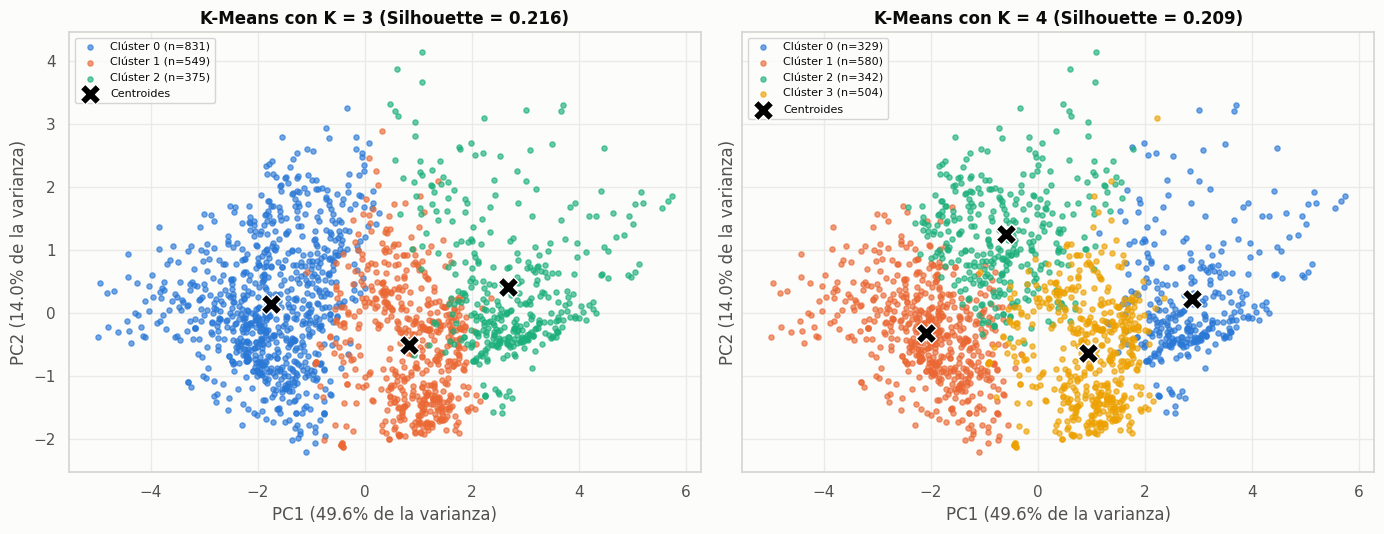

In [25]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for eje, k in zip(ejes, (3, 4)):
    etiquetas = resultados_kmeans[k]["etiquetas"]
    for grupo in range(k):
        viviendas_grupo = componentes_train[etiquetas == grupo]
        eje.scatter(viviendas_grupo["PC1"], viviendas_grupo["PC2"], s=14, alpha=0.65, color=PALETA[grupo],
                    label=f"Clúster {grupo} (n={len(viviendas_grupo)})")

    centroides = pd.DataFrame(resultados_kmeans[k]["modelo"].cluster_centers_, columns=VARIABLES_SELECCIONADAS)
    centroides_pc = pca.transform(centroides)
    eje.scatter(centroides_pc[:, 0], centroides_pc[:, 1], marker="X", s=220, c="black", edgecolor="white", label="Centroides")

    eje.set_title(f"K-Means con K = {k} (Silhouette = {resultados_kmeans[k]['silhouette']:.3f})")
    eje.set_xlabel(f"PC1 ({varianza_pc1:.1f}% de la varianza)")
    eje.set_ylabel(f"PC2 ({varianza_pc2:.1f}% de la varianza)")
    eje.legend(loc="upper left", fontsize=8)
plt.tight_layout()

guardar_figura("07_kmeans_k3_k4")
plt.show()

Los grupos aparecen como franjas contiguas a lo largo de PC1, sin separaciones claras entre ellos: las viviendas forman una nube continua y los grupos se tocan en los bordes. Esto es coherente con los valores bajos de Silhouette.

## 5.3 Perfil de los grupos

Para interpretar los grupos se utilizan sus **centroides**, que corresponden al promedio de cada variable dentro del grupo. Como K-Means trabajó con datos escalados, los centroides están en **unidades estandarizadas** y se leen así:

* **Valor positivo:** el grupo está sobre el promedio de entrenamiento en esa variable. Por ejemplo, 1,0 indica una desviación estándar por encima.
* **Valor negativo:** el grupo está bajo el promedio.
* **Valor cercano a 0:** el grupo se ubica en torno al promedio.

En las tablas, el rojo indica valores sobre el promedio y el azul valores bajo él. La columna `pct_precio_alto` muestra qué porcentaje de las viviendas del grupo se vendió sobre la mediana de precio. Se calcula **después** de formar los grupos y solo para interpretarlos, ya que K-Means no utilizó la etiqueta.

In [26]:
for k in (3, 4):
    etiquetas = resultados_kmeans[k]["etiquetas"]
    perfil = pd.DataFrame(resultados_kmeans[k]["modelo"].cluster_centers_, columns=VARIABLES_SELECCIONADAS)
    perfil["viviendas"] = np.bincount(etiquetas)
    perfil["pct_precio_alto"] = (y_train.groupby(etiquetas).mean().values * 100).round(0)
    perfil.index.name = f"Clúster (K = {k})"

    # Colores para leer los centroides: rojo sobre el promedio, azul bajo el promedio
    display(perfil.style
            .background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5, subset=VARIABLES_SELECCIONADAS)
            .format("{:.2f}", subset=VARIABLES_SELECCIONADAS)
            .format("{:.0f}%", subset=["pct_precio_alto"]))

,Overall Qual,Gr Liv Area,Garage Cars,Year Built,Full Bath,Total Bsmt SF,Year Remod/Add,Fireplaces,viviendas,pct_precio_alto
Clúster (K = 3),,,,,,,,,,
0,-0.70,-0.59,-0.65,-0.72,-0.81,-0.45,-0.64,-0.32,831,11%
1,0.23,0.15,0.28,0.55,0.71,-0.06,0.47,-0.14,549,75%
2,1.21,1.08,1.02,0.78,0.75,1.09,0.74,0.93,375,100%


,Overall Qual,Gr Liv Area,Garage Cars,Year Built,Full Bath,Total Bsmt SF,Year Remod/Add,Fireplaces,viviendas,pct_precio_alto
Clúster (K = 4),,,,,,,,,,
0,1.33,1.08,1.11,0.92,0.80,1.20,0.86,0.80,329,100%
1,-0.87,-0.80,-0.79,-0.67,-0.83,-0.55,-0.58,-0.84,580,3%
2,-0.23,0.08,-0.16,-0.71,-0.50,-0.12,-0.67,0.96,342,42%
3,0.28,0.17,0.30,0.65,0.77,-0.07,0.56,-0.20,504,77%


**Interpretación de los perfiles**

Con **K = 3**, los grupos siguen el mismo eje general que resume PC1, ya que en cada grupo casi todas las variables tienen el mismo signo.

| Clúster | Perfil | Viviendas | Sobre la mediana |
|---|---|---|---|
| 0 | **Básicas y antiguas.** Todas las variables bajo el promedio, en especial baños (−0,81), año de construcción (−0,72) y calidad (−0,70) | 831 | 11% |
| 1 | **Intermedias y modernas.** Calidad y tamaño cercanos al promedio, pero construcción y remodelación más recientes (0,55 y 0,47) y más baños (0,71) | 549 | 75% |
| 2 | **Premium.** Todas las variables sobre el promedio, con calidad (1,21), sótano (1,09) y superficie habitable (1,08) como las más altas | 375 | 100% |

Con **K = 4**, los clústeres premium e intermedio se mantienen con perfiles muy parecidos, y el grupo de viviendas básicas se divide en dos según la presencia de chimenea.

| Clúster | Perfil | Viviendas | Sobre la mediana |
|---|---|---|---|
| 0 | **Premium.** Todas las variables sobre el promedio, con calidad en 1,33 | 329 | 100% |
| 3 | **Intermedias y modernas.** Construcción reciente (0,65) y más baños (0,77), con calidad y tamaño cercanos al promedio | 504 | 77% |
| 2 | **Antiguas con chimenea.** Construidas y remodeladas hace más tiempo (−0,71 y −0,67), pero con chimenea (0,96) y superficie habitable en torno al promedio (0,08) | 342 | 42% |
| 1 | **Pequeñas y sencillas.** Las más bajas en casi todas las variables, incluida la chimenea (−0,84) | 580 | 3% |

El clúster 2 de K = 4 coincide con la dirección de PC2 descrita en la sección 4.3, que contrapone a las viviendas antiguas con chimenea frente a las más recientes. Además, aunque K-Means no utilizó el precio, la proporción de viviendas caras aumenta de forma ordenada desde los grupos más sencillos hasta los premium. Esto indica que los segmentos encontrados reflejan diferencias reales en el valor de las viviendas.

## Preguntas Act3

**¿Qué cambia al pasar de tres a cuatro clústeres?**

Con K = 3 los grupos siguen un gradiente de tamaño, antigüedad y calidad: viviendas pequeñas, antiguas y sencillas (831 casos, 11% sobre la mediana de precio), viviendas intermedias (549 casos, 75%) y viviendas grandes, nuevas y de buena calidad (375 casos, 100%).

Al pasar a K = 4, el grupo de viviendas grandes casi se mantiene (329 casos, 100% sobre la mediana), mientras que el grupo de viviendas pequeñas y antiguas se divide en dos. Uno tiene 580 casos, sin chimenea, y casi todo queda bajo la mediana (3% sobre ella). El otro, nuevo, tiene 342 casos con chimenea, antiguos y de calidad media, con una mezcla de precios (42% sobre la mediana). El grupo intermedio también se redistribuye un poco (504 casos, 77%). La inercia baja de 7.968 a 7.089, pero eso ocurre siempre al aumentar K y no indica por sí solo una mejor solución.

**¿Cuál de las dos soluciones obtuvo un mejor coeficiente Silhouette?**

K = 3, con 0,216 frente a 0,209 de K = 4. La diferencia es muy pequeña y ambos valores son bajos, lo que indica grupos poco separados que se tocan en los bordes, algo esperable en datos de viviendas, que forman un continuo. Una buena apariencia en el plano PC1 y PC2 no demuestra por sí sola que el agrupamiento sea de buena calidad.

**¿Cómo forma los grupos K-Means?**

K-Means elige K centroides iniciales y repite dos pasos: (1) asigna cada vivienda al centroide más cercano según la distancia euclidiana y (2) recalcula cada centroide como la media de las viviendas asignadas. El proceso termina cuando las asignaciones dejan de cambiar, buscando minimizar la suma de distancias al cuadrado dentro de cada grupo (inercia). Por eso depende de la escala de las variables, que aquí ya fueron estandarizadas, y tiende a formar grupos compactos de forma aproximadamente esférica. No utiliza la etiqueta `precio_alto`.

---
# 6. Ensambles (Actividad 4)

A diferencia de PCA y K-Means, que operan sin utilizar el precio, los ensambles abordan un problema de **clasificación supervisada**: predecir la etiqueta `precio_alto` (1 cuando la vivienda se vendió sobre la mediana de entrenamiento de $160.000 y 0 en caso contrario) a partir de las ocho variables seleccionadas en la Actividad 1.

Siguiendo el diseño definido en la sección 3.3.2, los modelos se entrenan únicamente con `X_train_escalado` e `y_train`, el conjunto de validación (`X_validacion_escalado`, `y_validacion`) se utiliza para seleccionar los hiperparámetros y verificar la ausencia de sobreajuste, y el conjunto de prueba (`X_test_escalado`, `y_test`) se emplea una sola vez al final para obtener las métricas oficiales.

---
## 6.1 Estrategias elegidas

Se comparan dos estrategias opuestas basadas en árboles de decisión:

| Estrategia | Modelo | Cómo combina los árboles | Qué reduce |
|---|---|---|---|
| **Bagging** | `RandomForestClassifier` | Entrena árboles profundos en paralelo sobre muestras aleatorias con reemplazo (*bootstrap*) y subconjuntos aleatorios de variables en cada división, promediando sus votos | La **varianza** |
| **Boosting** | `GradientBoostingClassifier` | Entrena árboles poco profundos de forma secuencial, donde cada nuevo árbol corrige los errores residuales del anterior | El **sesgo** |

Ambos modelos reciben `X_train_escalado` con `random_state=SEMILLA`. Aunque los árboles no dependen de la escala, se mantiene la misma matriz preparada en la sección 3.5.2 para conservar la imputación ajustada en entrenamiento y garantizar consistencia con el resto del flujo.

---
## 6.2 Ajuste de hiperparámetros con el conjunto de validación

Para cada estrategia se evalúa una grilla acotada de 12 combinaciones de hiperparámetros. Cada modelo se ajusta únicamente sobre **entrenamiento** y se mide en **validación**, conservando la configuración con mayor **F1-score** (utilizando **ROC-AUC** como desempate) y verificando además la brecha respecto a entrenamiento. El conjunto de prueba no interviene en esta selección.

In [27]:
from sklearn.model_selection import ParameterGrid

configuraciones = {
    "Random Forest (Bagging)": (
        RandomForestClassifier,
        {"random_state": SEMILLA, "n_jobs": -1},
        {"n_estimators": [100, 300], "max_depth": [None, 5, 8], "min_samples_leaf": [1, 5]},
    ),
    "Gradient Boosting (Boosting)": (
        GradientBoostingClassifier,
        {"random_state": SEMILLA},
        {"n_estimators": [100, 200, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]},
    ),
}

def metricas_clasificacion(modelo, X_evaluacion, y_evaluacion):
    prediccion = modelo.predict(X_evaluacion)
    return {
        "Accuracy": accuracy_score(y_evaluacion, prediccion),
        "Precision": precision_score(y_evaluacion, prediccion, pos_label=1, zero_division=0),
        "Recall": recall_score(y_evaluacion, prediccion, pos_label=1, zero_division=0),
        "F1": f1_score(y_evaluacion, prediccion, pos_label=1, zero_division=0),
        "AUC": roc_auc_score(y_evaluacion, modelo.predict_proba(X_evaluacion)[:, 1]),
    }

registro_validacion = []
for nombre, (clase_modelo, parametros_fijos, grilla) in configuraciones.items():
    for combinacion in ParameterGrid(grilla):
        modelo = clase_modelo(**parametros_fijos, **combinacion).fit(X_train_escalado, y_train)
        acc_train = accuracy_score(y_train, modelo.predict(X_train_escalado))
        metricas_val = metricas_clasificacion(modelo, X_validacion_escalado, y_validacion)
        registro_validacion.append({
            "ensamble": nombre,
            "parametros": combinacion,
            "Accuracy (train)": acc_train,
            **metricas_val,
            "Brecha (train - val)": acc_train - metricas_val["Accuracy"],
        })

tabla_validacion = pd.DataFrame(registro_validacion)

mejores_configuraciones = (
    tabla_validacion.sort_values(["F1", "AUC"], ascending=False)
    .groupby("ensamble", sort=False)
    .head(1)
    .set_index("ensamble")
)
parametros_elegidos = mejores_configuraciones["parametros"].to_dict()

print(f"Configuraciones probadas: {len(tabla_validacion)} ({tabla_validacion['ensamble'].value_counts().to_dict()})")
print("\nConfiguración elegida de cada ensamble (métricas en validación):")
for nombre, fila in mejores_configuraciones.iterrows():
    print(f"  {nombre}: {fila['parametros']}")
display(mejores_configuraciones.drop(columns="parametros").round(4))

Configuraciones probadas: 24 ({'Random Forest (Bagging)': 12, 'Gradient Boosting (Boosting)': 12})

Configuración elegida de cada ensamble (métricas en validación):
  Random Forest (Bagging): {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 300}
  Gradient Boosting (Boosting): {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}


,Accuracy (train),Accuracy,Precision,Recall,F1,AUC,Brecha (train - val)
ensamble,,,,,,,
Random Forest (Bagging),0.9430,0.9333,0.9338,0.9306,0.9322,0.9762,0.0097
Gradient Boosting (Boosting),0.9202,0.9316,0.9218,0.9410,0.9313,0.9775,-0.0114


En validación ambos ensambles quedan prácticamente empatados: **Random Forest** (`n_estimators=300`, `max_depth=None`, `min_samples_leaf=5`) alcanza un F1-score de **0,9322** y **Gradient Boosting** (`n_estimators=100`, `learning_rate=0,05`, `max_depth=2`) obtiene **0,9313**, ambos con brechas acotadas respecto a entrenamiento que descartan sobreajuste severo. Gradient Boosting muestra un Recall (**0,9410**) y un AUC (**0,9775**) levemente superiores, mientras que Random Forest lidera ligeramente en Precision (**0,9338**) y Accuracy (**0,9333**). Dado este empate técnico en validación, la comparación definitiva se realiza sobre el conjunto de prueba.

---
## 6.3 Evaluación final en el conjunto de prueba

Con las configuraciones seleccionadas y entrenadas exclusivamente sobre `X_train_escalado`, se realiza la medición única y final sobre el conjunto de **prueba** (585 viviendas: 291 bajo la mediana y 294 sobre la mediana). Accuracy, Precision, Recall y F1-score se calculan para la clase 1 (`precio_alto = 1`), junto con el área bajo la curva ROC (**AUC**).

In [28]:
modelos_finales = {
    nombre: configuraciones[nombre][0](**configuraciones[nombre][1], **parametros_elegidos[nombre]).fit(X_train_escalado, y_train)
    for nombre in configuraciones
}

resultados_test = pd.DataFrame(
    {nombre: metricas_clasificacion(modelo, X_test_escalado, y_test) for nombre, modelo in modelos_finales.items()}
).T
display(resultados_test.round(4))

,Accuracy,Precision,Recall,F1,AUC
Random Forest (Bagging),0.9504,0.9617,0.9388,0.9501,0.9815
Gradient Boosting (Boosting),0.9333,0.9474,0.9184,0.9326,0.9794


En el conjunto de prueba **Random Forest** supera a **Gradient Boosting** en las cinco métricas evaluadas: alcanza un Accuracy de **0,9504** frente a **0,9333** (+1,71 puntos porcentuales), un F1-score de **0,9501** frente a **0,9326** y un AUC de **0,9815** frente a **0,9794**.

El siguiente gráfico compara visualmente las cuatro métricas principales de clasificación.

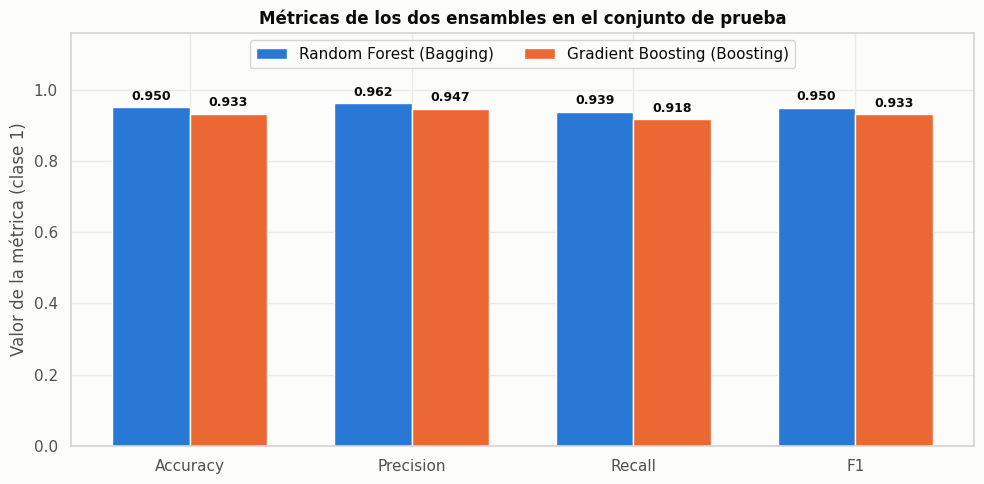

In [29]:
metricas_pauta = ["Accuracy", "Precision", "Recall", "F1"]
fig, eje = plt.subplots(figsize=(10, 5))
ancho = 0.35
posiciones = np.arange(len(metricas_pauta))

for desplazamiento, (nombre, color) in zip(
    [-ancho / 2, ancho / 2], zip(resultados_test.index, [COLOR_PRINCIPAL, COLOR_SECUNDARIO])
):
    barras = eje.bar(
        posiciones + desplazamiento,
        resultados_test.loc[nombre, metricas_pauta],
        ancho,
        label=nombre,
        color=color,
    )
    eje.bar_label(barras, fmt="%.3f", fontsize=9, fontweight="bold", padding=3)

eje.set_xticks(posiciones)
eje.set_xticklabels(metricas_pauta)
eje.set_ylim(0, 1.16)
eje.set_ylabel("Valor de la métrica (clase 1)")
eje.set_title("Métricas de los dos ensambles en el conjunto de prueba")
eje.legend(loc="upper center", ncol=2, frameon=True)
plt.tight_layout()
guardar_figura("08_ensambles_metricas")
plt.show()

Random Forest aventaja a Gradient Boosting en las cuatro barras: la mayor diferencia aparece en **Recall** (**0,939** frente a **0,918**, +2,04 puntos), seguida de **Accuracy** y **F1-score** (~1,7 puntos) y **Precision** (**0,962** frente a **0,947**, +1,43 puntos). En ambos modelos la precisión supera al recall.

Para desglosar cuántos errores corresponden a falsos positivos y cuántos a falsos negativos, se presentan las **matrices de confusión** sobre las 585 viviendas de prueba.

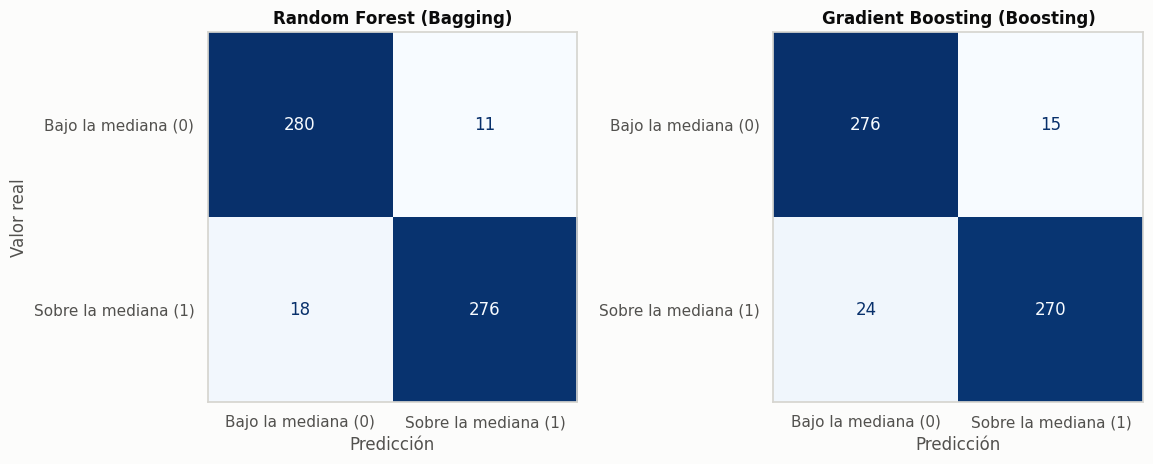

,Verdaderos negativos,Falsos positivos,Falsos negativos,Verdaderos positivos
Random Forest (Bagging),280,11,18,276
Gradient Boosting (Boosting),276,15,24,270


In [30]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for posicion, (eje, (nombre, modelo)) in enumerate(zip(ejes, modelos_finales.items())):
    ConfusionMatrixDisplay.from_estimator(
        modelo,
        X_test_escalado,
        y_test,
        display_labels=["Bajo la mediana (0)", "Sobre la mediana (1)"],
        cmap="Blues",
        colorbar=False,
        ax=eje,
    )
    eje.set_title(nombre)
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Valor real" if posicion == 0 else "")
    eje.grid(False)

plt.tight_layout()
guardar_figura("09_ensambles_matrices_confusion")
plt.show()

tabla_confusion = pd.DataFrame({
    nombre: dict(
        zip(
            ["Verdaderos negativos", "Falsos positivos", "Falsos negativos", "Verdaderos positivos"],
            confusion_matrix(y_test, modelo.predict(X_test_escalado)).ravel(),
        )
    )
    for nombre, modelo in modelos_finales.items()
}).T
display(tabla_confusion)

Sobre las 585 viviendas de prueba, **Random Forest** acierta **556 casos** y comete **29 errores** (**11 falsos positivos** y **18 falsos negativos**), mientras que **Gradient Boosting** acierta **546 casos** y acumula **39 errores** (**15 falsos positivos** y **24 falsos negativos**), es decir, 10 errores más. En ambos ensambles predominan los falsos negativos (viviendas vendidas sobre la mediana clasificadas como precio bajo), lo que explica que el Recall sea la métrica más baja.

Para evaluar la capacidad de discriminación de probabilidades a lo largo de todos los umbrales de decisión posibles, se grafican ambas **curvas ROC** en una misma figura con sus respectivos valores de **AUC**.

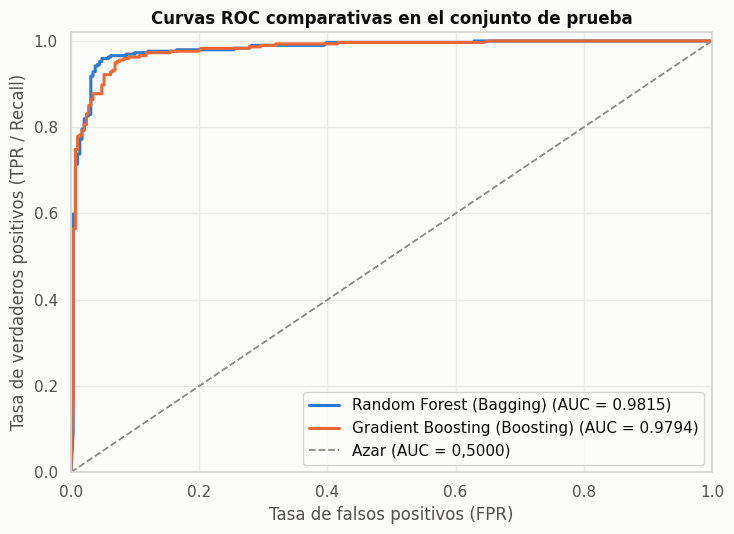

In [31]:
fig, eje = plt.subplots(figsize=(7.5, 5.5))
for (nombre, modelo), color in zip(modelos_finales.items(), [COLOR_PRINCIPAL, COLOR_SECUNDARIO]):
    fpr, tpr, _ = roc_curve(y_test, modelo.predict_proba(X_test_escalado)[:, 1])
    eje.plot(fpr, tpr, color=color, linewidth=2.2, label=f"{nombre} (AUC = {resultados_test.loc[nombre, 'AUC']:.4f})")

eje.plot([0, 1], [0, 1], color=COLOR_NEUTRO, linestyle="--", linewidth=1.3, label="Azar (AUC = 0,5000)")
eje.set_xlabel("Tasa de falsos positivos (FPR)")
eje.set_ylabel("Tasa de verdaderos positivos (TPR / Recall)")
eje.set_title("Curvas ROC comparativas en el conjunto de prueba")
eje.set_xlim(0, 1)
eje.set_ylim(0, 1.02)
eje.legend(loc="lower right")
plt.tight_layout()
guardar_figura("10_ensambles_roc")
plt.show()

Ambas curvas ROC se elevan rápidamente hacia la esquina superior izquierda y casi se superponen, alcanzando un AUC de **0,9815** para Random Forest y **0,9794** para Gradient Boosting. La diferencia de AUC (**0,0021**) es mucho menor que en Accuracy o F1-score, ya que el AUC mide el ordenamiento global de probabilidades en todos los umbrales, mientras que las métricas de clasificación dependen del corte fijo en 0,50.

---
## 6.4 Conclusiones y respuestas
**Pregunta: ¿Cuál de los dos ensambles obtuvo mejores resultados?**

**Random Forest (Bagging)** obtuvo mejores resultados en el conjunto de prueba, superando a **Gradient Boosting** en las cinco métricas: Accuracy (**0,9504** frente a **0,9333**), Precision (**0,9617** frente a **0,9474**), Recall (**0,9388** frente a **0,9184**), F1-score (**0,9501** frente a **0,9326**) y AUC (**0,9815** frente a **0,9794**), con 29 errores totales frente a 39. La ventaja es consistente en prueba (10 viviendas de diferencia sobre 585), aunque en validación ambos habían quedado prácticamente empatados (F1 de **0,9322** y **0,9313**), y ambos superan ampliamente el 50% de un clasificador aleatorio.

**Pregunta: ¿En qué métricas se observan las principales diferencias?**

Las mayores diferencias aparecen en **Recall** (**0,9388** frente a **0,9184**, una brecha de **2,04** puntos porcentuales), seguida de **Accuracy** (**+1,71** puntos), **F1-score** (**+1,75** puntos) y **Precision** (**+1,43** puntos). En cambio, el **AUC** varía apenas en **0,0021** puntos (**0,9815** frente a **0,9794**). Esto indica que ambos modelos ordenan de manera muy similar las probabilidades de pertenecer al segmento alto, pero Random Forest comete menos errores cerca del umbral de decisión de 0,50, reduciendo tanto los falsos negativos (18 frente a 24) como los falsos positivos (11 frente a 15).

**Pregunta: ¿Cuál recomendarían para este problema y por qué?**

Se recomienda **Random Forest (Bagging)** para este problema, porque obtiene los valores más altos en las cuatro métricas de clasificación y en el AUC sobre el conjunto de prueba, reduce tanto los falsos positivos como los falsos negativos (29 errores frente a 39) y su configuración fue seleccionada limpiamente usando solo entrenamiento y validación. El submuestreo aleatorio tanto de viviendas como de variables en cada división permite capturar las interacciones entre calidad, superficie y antigüedad sin sobreajustar. Como matiz, dado que en validación el desempeño fue prácticamente idéntico, Gradient Boosting sigue siendo una alternativa sólida si se buscara un modelo más compacto (100 árboles de profundidad 2).


---
# 7. Comparación y conclusiones (Actividad 5)

| K-Means | Clústeres | Silhouette |
|---|---|---|
| K = 3 | 3 | 0.216 |
| K = 4 | 4 | 0.209 |

.

| Ensamble | Accuracy | F1-score | ROC-AUC |
|---|---|---|---|
| Random Forest (Bagging) | 0.9504 | 0.9501 | 0.9815 |
| Gradient Boosting (Boosting) | 0.9333 | 0.9326 | 0.9794 |


Cabe recordar que una buena separación visual en el plano PC1 y PC2 no demuestra por sí sola que el agrupamiento sea de buena calidad.

1. **¿Qué valor de K produjo los grupos mejor definidos según Silhouette?**

**K = 3** obtuvo el mayor coeficiente Silhouette (**0,216** frente a **0,209** de K = 4), produciendo grupos levemente mejor definidos. Sin embargo, la diferencia es mínima (0,007) y ambos valores son bajos porque las viviendas forman una nube continua sin fronteras naturales marcadas —como se observó al proyectarlos en el plano PC1 y PC2, donde los clústeres aparecen como franjas contiguas que se tocan en los bordes—. Por ello, aunque K = 3 resulta preferible por parsimonia y mayor cohesión relativa, los grupos deben interpretarse como segmentos graduales de un continuo y no como particiones aisladas.

2. **¿Qué ensamble elegirían según las métricas de clasificación?**

Se elegiría **Random Forest (Bagging)**, ya que en el conjunto de prueba supera a Gradient Boosting en las tres métricas resumen: **Accuracy** (**0,9504** frente a **0,9333**), **F1-score** (**0,9501** frente a **0,9326**) y **ROC-AUC** (**0,9815** frente a **0,9794**), reduciendo el total de errores en prueba de 39 a 29 sobre 585 viviendas. Además, su configuración (`n_estimators=300`, `max_depth=None`, `min_samples_leaf=5`) fue seleccionada mediante validación sin tocar el conjunto de prueba, mostrando una generalización sólida y equilibrada entre Precision (0,9617) y Recall (0,9388).

3. **¿Qué utilidad podrían tener los grupos identificados por K-Means en este dataset?**

Aunque K-Means no utilizó el precio ni los datos de prueba, los perfiles encontrados capturan diferencias estructurales reales del mercado inmobiliario de Ames que resultan útiles para **segmentación comercial y análisis exploratorio**:
   * **Identificación de gamas de vivienda:** con K = 3 se distinguen de forma ordenada viviendas *básicas y antiguas* (831 casos, solo 11% sobre la mediana), *intermedias y modernas* (549 casos, 75%) y *premium* (375 casos, 100%).
   * **Detección de subperfiles específicos:** al pasar a K = 4, emerge un segmento de *viviendas antiguas con chimenea y superficie media* (342 casos, 42% sobre la mediana) frente a *viviendas pequeñas sin chimenea* (580 casos, 3%), replicando el patrón capturado por PC2.
   * **Aplicaciones prácticas:** permiten definir carteras comparables para tasación inicial, diseñar campañas de remodelación focalizadas en propiedades antiguas de tamaño medio o caracterizar el inventario disponible sin depender de etiquetas previas.

4. **¿En qué se diferencia el objetivo de K-Means del objetivo de los ensambles utilizados?**

Se diferencian fundamentalmente en el **paradigma de aprendizaje y el uso de la variable objetivo**:
   * **K-Means (aprendizaje no supervisado):** recibe únicamente las ocho variables físicas estandarizadas (`X_train_escalado`), sin conocer `precio_alto`. Su objetivo es **descriptivo y exploratorio**: descubrir cómo se organizan internamente las viviendas en grupos homogéneos minimizando la distancia euclidiana intra-clúster (inercia).
   * **Random Forest y Gradient Boosting (aprendizaje supervisado):** reciben tanto las variables predictoras como la etiqueta `precio_alto` durante el entrenamiento. Su objetivo es **predictivo**: aprender fronteras de decisión que permitan clasificar viviendas nuevas según la probabilidad de venderse sobre o bajo la mediana de $160.000, evaluando su desempeño mediante métricas de acierto y discriminación frente a una respuesta conocida.

---
# 8. Referencias

* De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project*. Journal of Statistics Education, 19(3).